# Parte Específica — Classificador do Pump it Up

Projeto Final AVD 2026.2 — Grupo 6. Responsável: **Gustavo**.

Complemento preditivo da EDA (`src/parte_especifica/eda.ipynb`), lendo **exclusivamente** o dataset tratado em `data/parte_especifica/clean/pump_it_up_clean.csv`.

> **Sobre o uso de IA neste notebook:** as células de código marcadas com `# [IA]` foram geradas com apoio de IA para implementar o pipeline de classificação, as métricas e os gráficos dentro do escopo das Aulas 25 e 26. Toda interpretação e discussão crítica dos resultados é autoral do grupo e fica na seção `[AUTORAL]` ao final.

## Índice e como ler este notebook

- [0. Objetivo e vínculo com a pergunta de pesquisa](#sec-0)
- [Configuração](#sec-config)
- [1. Carga do dataset tratado (`clean/`)](#sec-1)
- [2. Preparação anti-data leakage e divisão estratificada](#sec-2)
- [3. Pipeline de pré-processamento (Cascata + One-Hot + Target Encoding)](#sec-3)
- [4. Treinamento dos modelos (Árvore de Decisão e Random Forest)](#sec-4)
- [5. Avaliação: matriz de confusão, métricas por classe e importância](#sec-5)
  - [5.5 Demonstração prática: 3 bombas reais do teste + auditoria da Árvore](#sec-5-5)
- [6. Interpretação autoral dos resultados](#sec-6)

**Legenda**
- `# [IA]` no início de cada célula de código: código feito com apoio de IA.
- `> **O que este código faz (para explicar ao vivo):**` resumo direto da lógica de cada etapa para a arguição.
- `> **Como ler:**` explica apenas como ler a tabela ou gráfico, sem interpretar o resultado.

<a id="sec-0"></a>

## 0. Objetivo e vínculo com a pergunta de pesquisa

**Pergunta de pesquisa (definida na Seção 0.1 da EDA):** *"Quais características de um ponto d'água se associam ao seu estado operacional (funcional, precisando de reparo ou não funcional) e em que medida esses atributos permitem classificar/identificar corretamente bombas com necessidade de manutenção ou inoperantes?"*

Enquanto a EDA responde à primeira parte (quais características se associam ao estado das bombas), este notebook responde à segunda parte aplicando as técnicas vistas nas **Aulas 25 e 26**:
- Divisão **treino/teste estratificada** (80% / 20%, preservando as proporções das 3 classes);
- **Imputação em cascata** (`lga → region → basin`) e **encodings** (**One-Hot Encoding** para nominais de baixa cardinalidade; **Target Encoding** para nominais de alta cardinalidade) ajustados **somente no treino** dentro de um `Pipeline` (zero *data leakage*);
- Comparação entre **Árvore de Decisão** (baseline interpretável) e **Random Forest** (modelo principal);
- Avaliação via **matriz de confusão**, **acurácia**, **precisão**, **recall** e **F1 por classe**.

<a id="sec-config"></a>

## Configuração

**Rodando no Google Colab?** Rode a célula abaixo primeiro para clonar o repositório e ter acesso a `data/parte_especifica/clean/pump_it_up_clean.csv`. Localmente ela não altera nada.

In [1]:
# [IA] Gemini – prepara o ambiente quando o notebook roda no Google Colab (clona o repositório)
import os, subprocess, sys
from pathlib import Path

if "google.colab" in sys.modules:
    repo = Path("/content/projeto-avd-2026-2-pump-it-up-classificatorio")
    if not repo.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/Fyre-Flye/projeto-avd-2026-2-pump-it-up-classificatorio.git",
                        str(repo)], check=True)
    os.chdir(repo)
    print("Colab pronto. Pasta atual:", Path.cwd())
else:
    print("Ambiente local.")

Ambiente local.


In [2]:
# [IA] Gemini – configuração: imports permitidos (Aulas 25–26), caminhos, paleta acessível e funções auxiliares
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, TargetEncoder
from sklearn.tree import DecisionTreeClassifier

# Localiza a raiz do repositório automaticamente
ROOT = Path.cwd()
while not (ROOT / "requirements.txt").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

CLEAN_PATH = ROOT / "data" / "parte_especifica" / "clean" / "pump_it_up_clean.csv"
OUT_DIR = ROOT / "out" / "parte_especifica"
if not CLEAN_PATH.exists():
    raise FileNotFoundError(
        "Não achei data/parte_especifica/clean/pump_it_up_clean.csv. "
        "Rode antes a Seção 6 do eda.ipynb para gerar o CSV tratado."
    )
OUT_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
COL_ALVO = "status_group"
STATUS_ORDEM = ["functional", "functional needs repair", "non functional"]
STATUS_CURTO = ["functional", "needs repair", "non functional"]

# Paleta Okabe-Ito (acessível para daltonismo, Aula 05)
COR_DT = "#E69F00"   # Árvore de Decisão (baseline)
COR_RF = "#0072B2"   # Random Forest (principal)

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "font.size": 12, "axes.titlesize": 14, "axes.labelsize": 12,
    "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 11,
    "figure.dpi": 110,
})

GLOSSARIO_COLUNAS = {
    "amount_tsh": "Água disponível (total static head)",
    "gps_height": "Altitude do poço",
    "longitude": "Longitude GPS",
    "latitude": "Latitude GPS",
    "population": "População ao redor do poço",
    "construction_year": "Ano de construção",
    "ano_registro": "Ano do registro",
    "idade_no_registro": "Idade do poço no registro",
    "ausente_population": "Flag: population era 0",
    "ausente_construction_year": "Flag: construction_year era 0",
    "ausente_gps_height": "Flag: gps_height era 0",
    "ausente_coords": "Flag: coordenadas eram 0",
    "quantity": "Quantidade de água",
    "extraction_type_class": "Tipo de extração (geral)",
    "waterpoint_type_group": "Tipo de ponto d'água (geral)",
    "payment_type": "Forma de pagamento",
    "quality_group": "Qualidade da água (geral)",
    "source_class": "Fonte da água (geral)",
    "management_group": "Gestão do poço (geral)",
    "scheme_management": "Operador do esquema",
    "basin": "Bacia hidrográfica",
    "region": "Região geográfica",
    "public_meeting": "Reunião pública (bool)",
    "permit": "Possui licença/permissão",
    "lga": "Autoridade local / município",
    "ward": "Subdistrito / ward",
    "funder": "Financiador do poço",
    "installer": "Instalador do poço",
}


def salvar(fig, nome):
    """Salva figura em out/parte_especifica/<nome>.png (com retry para travas do OneDrive)."""
    destino = OUT_DIR / f"{nome}.png"
    for tentativa in range(5):
        try:
            fig.savefig(destino, dpi=150, bbox_inches="tight")
            return
        except OSError:
            if tentativa == 4:
                raise
            time.sleep(0.5)


def com_titulo(obj, titulo):
    """Aplica título (caption) legível em DataFrame ou Styler do pandas."""
    styler = obj.style if isinstance(obj, pd.DataFrame) else obj
    return styler.set_caption(titulo).set_table_styles([{
        "selector": "caption",
        "props": [("font-size", "14px"), ("font-weight", "bold"), ("text-align", "left"), ("padding", "4px 0 8px 0")],
    }], overwrite=False)


print("Raiz encontrada:", ROOT.name)
print("Arquivo de entrada:", CLEAN_PATH.relative_to(ROOT))

Raiz encontrada: projeto-avd-2026-2-pump-it-up-classificatorio
Arquivo de entrada: data\parte_especifica\clean\pump_it_up_clean.csv


<a id="sec-1"></a>

## 1. Carga do dataset tratado (`clean/`)

Carrega exclusivamente o arquivo exportado ao final da EDA (`data/parte_especifica/clean/pump_it_up_clean.csv`) e confere dimensões, nulos e distribuição da variável-alvo.

> **O que este código faz (para explicar ao vivo):** lê o CSV limpo gerado pela Seção 6 da EDA e confirma que existem 59.333 linhas, 31 colunas e 0 valores nulos antes de iniciar a preparação do modelo.

In [3]:
# [IA] Gemini – carga do dataset tratado (lendo exclusivamente de data/parte_especifica/clean/)
df = pd.read_csv(CLEAN_PATH)
print(f"Dimensões: {df.shape[0]:,} linhas × {df.shape[1]} colunas")
print("Total de nulos:", int(df.isna().sum().sum()))

dist_alvo = pd.DataFrame({
    "n": df[COL_ALVO].value_counts().reindex(STATUS_ORDEM),
    "pct": (df[COL_ALVO].value_counts(normalize=True).reindex(STATUS_ORDEM) * 100).round(2),
})
com_titulo(dist_alvo.style.format({"n": "{:,.0f}", "pct": "{:.2f}%"}), "Tabela 1.1 — Distribuição das classes no dataset tratado")

Dimensões: 59,333 linhas × 31 colunas


Total de nulos: 0


,n,pct
status_group,,
functional,"32,226",54.31%
functional needs repair,"4,313",7.27%
non functional,"22,794",38.42%


<a id="sec-2"></a>

## 2. Preparação anti-*data leakage* e divisão estratificada (Aula 26)

### 2.1 Reversão controlada das imputações antes do split

> **O que este código faz (para explicar ao vivo):** no `pump_it_up_clean.csv`, as colunas `population`, `construction_year`, `gps_height`, `longitude` e `latitude` já vieram imputadas com a mediana da base inteira para alimentar o dashboard Streamlit sem nulos. Porém, para o classificador, usar medianas calculadas com dados do conjunto de teste causaria **data leakage** (vazamento de dados, Aula 26). Por isso, usando as 4 flags `ausente_*` salvas na EDA, devolvemos esses valores originalmente ausentes para `NaN` **antes** de dividir treino e teste, e fazemos a imputação em cascata **dentro do `Pipeline`**, aprendendo medianas apenas em `X_train`!

In [4]:
# [IA] Gemini – separa features e alvo, revertendo valores imputados para NaN antes do split (evita data leakage)
COLUNAS_IGNORAR = ["id", "date_recorded", COL_ALVO, "idade_no_registro"]
X = df.drop(columns=COLUNAS_IGNORAR).copy()
y = df[COL_ALVO].copy()

# Reverte para NaN exatamente onde o dado original era ausente/zerado (usando as flags da Seção 6)
X.loc[X["ausente_population"] == 1, "population"] = np.nan
X.loc[X["ausente_construction_year"] == 1, "construction_year"] = np.nan
X.loc[X["ausente_gps_height"] == 1, "gps_height"] = np.nan
X.loc[X["ausente_coords"] == 1, ["longitude", "latitude"]] = np.nan

print("Features de entrada (antes de derivar idade_no_registro no Pipeline):", X.shape[1])
print("NaNs restaurados para imputação exclusiva no treino:")
print(X[["population", "construction_year", "gps_height", "longitude", "latitude"]].isna().sum().to_string())

Features de entrada (antes de derivar idade_no_registro no Pipeline): 27
NaNs restaurados para imputação exclusiva no treino:
population           21333
construction_year    20659
gps_height           20390
longitude             1777
latitude              1777


### 2.2 Divisão treino/teste estratificada (80% treino / 20% teste)

> **O que este código faz (para explicar ao vivo):** divide a base em **80% treino** e **20% teste** usando `stratify=y` e `random_state=42`. A estratificação (Aula 26) garante que a classe minoritária (`functional needs repair`, 7,3%) apareça exatamente na mesma proporção no treino e no teste, evitando sorteios enviesados.

In [5]:
# [IA] Gemini – divisão hold-out estratificada (80% treino, 20% teste, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

conf_split = pd.DataFrame({
    "treino_n": y_train.value_counts().reindex(STATUS_ORDEM),
    "treino_pct": (y_train.value_counts(normalize=True).reindex(STATUS_ORDEM) * 100).round(2),
    "teste_n": y_test.value_counts().reindex(STATUS_ORDEM),
    "teste_pct": (y_test.value_counts(normalize=True).reindex(STATUS_ORDEM) * 100).round(2),
})
print(f"Treino: {len(X_train):,} linhas (80%) | Teste: {len(X_test):,} linhas (20%)")
com_titulo(
    conf_split.style.format({"treino_n": "{:,.0f}", "treino_pct": "{:.2f}%", "teste_n": "{:,.0f}", "teste_pct": "{:.2f}%"}),
    "Tabela 2.1 — Conferência da estratificação (proporção das classes em treino vs. teste)"
)

Treino: 47,466 linhas (80%) | Teste: 11,867 linhas (20%)

,treino_n,treino_pct,teste_n,teste_pct
status_group,,,,
functional,"25,781",54.31%,"6,445",54.31%
functional needs repair,"3,450",7.27%,863,7.27%
non functional,"18,235",38.42%,"4,559",38.42%


<a id="sec-3"></a>

## 3. Pipeline de pré-processamento (Imputação em Cascata + One-Hot + Target Encoding)

### 3.1 Definição das listas de colunas e do `ImputadorCascata`

> **O que este código faz (para explicar ao vivo):**
> 1. **`ImputadorCascata`** (herda de `BaseEstimator, TransformerMixin` do `scikit-learn`): no método `.fit(X_train)`, guarda em memória apenas as medianas do **treino** agrupadas por `lga`, `region`, `basin` e a mediana global. No método `.transform(X)`, preenche os `NaN` seguindo a cascata `lga → region → basin → global`, garante `gps_height >= 0` e calcula `idade_no_registro = ano_registro - construction_year`.
> 2. **`ColumnTransformer`** aplica o encoding certo para cada grupo (tabela *"Qual Encoding Usar?"*, **Aula 26, pág. 15**):
>    - **Numéricas + flags (12 colunas):** entram direto (`passthrough`), pois árvores não precisam de normalização;
>    - **Nominais de baixa cardinalidade (12 colunas):** `OneHotEncoder(handle_unknown="ignore")` (gera colunas binárias 0/1 sem impor ordem);
>    - **Nominais de alta cardinalidade (4 colunas — `lga`, `ward`, `funder`, `installer`):** `TargetEncoder(smooth="auto", random_state=42)` (troca cada categoria pela proporção das 3 classes de `status_group`, usando *cross-fitting* interno no treino para evitar overfitting e *data leakage*).

In [6]:
# [IA] Gemini – transformador de imputação em cascata (só no treino) + ColumnTransformer (One-Hot e Target Encoding)
COLS_IMPUTAR = ["population", "construction_year", "gps_height", "longitude", "latitude"]

COLS_NUM = [
    "amount_tsh", "gps_height", "longitude", "latitude",
    "population", "construction_year", "ano_registro", "idade_no_registro",
    "ausente_population", "ausente_construction_year", "ausente_gps_height", "ausente_coords",
]

COLS_CAT_BAIXA = [
    "quantity", "extraction_type_class", "waterpoint_type_group", "payment_type",
    "quality_group", "source_class", "management_group", "scheme_management",
    "basin", "region", "public_meeting", "permit",
]

COLS_CAT_ALTA = ["lga", "ward", "funder", "installer"]


class ImputadorCascata(BaseEstimator, TransformerMixin):
    """Aprende medianas por lga -> region -> basin -> global SOMENTE no treino e deriva idade_no_registro."""

    def __init__(self, colunas=COLS_IMPUTAR, grupos=("lga", "region", "basin")):
        self.colunas = colunas
        self.grupos = grupos

    def fit(self, X, y=None):
        self.medianas_ = {}
        self.mediana_global_ = {}
        for col in self.colunas:
            self.medianas_[col] = {g: X.groupby(g)[col].median().to_dict() for g in self.grupos}
            self.mediana_global_[col] = float(X[col].median())
        return self

    def transform(self, X):
        X_out = X.copy()
        for col in self.colunas:
            serie = X_out[col].copy()
            for g in self.grupos:
                mapa = self.medianas_[col][g]
                serie = serie.fillna(X_out[g].map(mapa))
            X_out[col] = serie.fillna(self.mediana_global_[col])
        X_out["gps_height"] = X_out["gps_height"].clip(lower=0)
        X_out["idade_no_registro"] = (X_out["ano_registro"] - X_out["construction_year"]).clip(lower=0)
        return X_out


def criar_preprocessador():
    """Cria um ColumnTransformer novo (sem estado compartilhado entre modelos)."""
    return ColumnTransformer(
        transformers=[
            ("num", "passthrough", COLS_NUM),
            ("cat_baixa", OneHotEncoder(handle_unknown="ignore", sparse_output=False), COLS_CAT_BAIXA),
            ("cat_alta", TargetEncoder(smooth="auto", random_state=RANDOM_STATE), COLS_CAT_ALTA),
        ],
        remainder="drop",
    )


print(f"Grupos de features -> Numéricas/flags: {len(COLS_NUM)} | Baixa card. (One-Hot): {len(COLS_CAT_BAIXA)} | Alta card. (Target): {len(COLS_CAT_ALTA)}")

Grupos de features -> Numéricas/flags: 12 | Baixa card. (One-Hot): 12 | Alta card. (Target): 4


<a id="sec-4"></a>

## 4. Treinamento dos modelos (Aula 25)

### 4.1 Baseline: Árvore de Decisão (`DecisionTreeClassifier`)

> **O que este código faz (para explicar ao vivo):** monta um `Pipeline` completo (`ImputadorCascata → ColumnTransformer → DecisionTreeClassifier`), ajusta com `.fit(X_train, y_train)` e gera previsões em `X_test`. Usamos `max_depth=15` e `min_samples_leaf=5` para evitar que a árvore única cresça sem limite e decore o conjunto de treino (overfitting). Também exibimos a acurácia no treino vs. teste para inspecionar o grau de sobreajuste.

In [7]:
# [IA] Gemini – Pipeline e treinamento do baseline: DecisionTreeClassifier (Aula 25, pág. 22)
pipe_dt = Pipeline([
    ("imputacao", ImputadorCascata()),
    ("encoding", criar_preprocessador()),
    ("modelo", DecisionTreeClassifier(max_depth=15, min_samples_leaf=5, random_state=RANDOM_STATE)),
])

t0 = time.perf_counter()
pipe_dt.fit(X_train, y_train)
tempo_dt = time.perf_counter() - t0

pred_dt_train = pipe_dt.predict(X_train)
pred_dt_test = pipe_dt.predict(X_test)

acc_dt_train = accuracy_score(y_train, pred_dt_train)
acc_dt_test = accuracy_score(y_test, pred_dt_test)

print(f"Árvore de Decisão treinada em {tempo_dt:.2f}s")
print(f"Acurácia treino: {acc_dt_train*100:.2f}% | Acurácia teste: {acc_dt_test*100:.2f}% | Diferença (gap): {(acc_dt_train - acc_dt_test)*100:.2f} pp")

C:\Users\gusta\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


Árvore de Decisão treinada em 1.35s
Acurácia treino: 79.85% | Acurácia teste: 75.33% | Diferença (gap): 4.51 pp


### 4.2 Modelo principal: Random Forest (`RandomForestClassifier`)

> **O que este código faz (para explicar ao vivo):** usa exatamente o mesmo pré-processamento sem *data leakage*, mas troca o classificador por um **`RandomForestClassifier`** com `n_estimators=200` árvores treinadas em amostras bootstrap e votação majoritária (Aula 25, pág. 23), usando `min_samples_leaf=2` para reduzir sobreajuste e `n_jobs=-1` para rodar em paralelo na CPU.

In [8]:
# [IA] Gemini – Pipeline e treinamento do modelo principal: RandomForestClassifier (Aula 25, pág. 23)
pipe_rf = Pipeline([
    ("imputacao", ImputadorCascata()),
    ("encoding", criar_preprocessador()),
    ("modelo", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )),
])

t0 = time.perf_counter()
pipe_rf.fit(X_train, y_train)
tempo_rf = time.perf_counter() - t0

pred_rf_train = pipe_rf.predict(X_train)
pred_rf_test = pipe_rf.predict(X_test)

acc_rf_train = accuracy_score(y_train, pred_rf_train)
acc_rf_test = accuracy_score(y_test, pred_rf_test)

print(f"Random Forest treinado em {tempo_rf:.2f}s")
print(f"Acurácia treino: {acc_rf_train*100:.2f}% | Acurácia teste: {acc_rf_test*100:.2f}% | Diferença (gap): {(acc_rf_train - acc_rf_test)*100:.2f} pp")

C:\Users\gusta\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


Random Forest treinado em 2.52s
Acurácia treino: 86.93% | Acurácia teste: 80.58% | Diferença (gap): 6.35 pp


<a id="sec-5"></a>

## 5. Avaliação: matriz de confusão, métricas por classe e importância (Aula 26)

### 5.1 Matrizes de confusão lado a lado (Árvore de Decisão vs. Random Forest)

Compara a matriz de confusão dos dois modelos no conjunto de teste (`n = 11.867`), mostrando em cada célula tanto o **percentual sobre a classe real (recall por linha)** quanto a **contagem absoluta**.

> **Como ler:** As linhas são a classe real (`status_group`) e as colunas são a classe prevista pelo modelo. A diagonal principal mostra os acertos (em % de recall daquela classe e em número de bombas); fora da diagonal estão os erros de classificação.

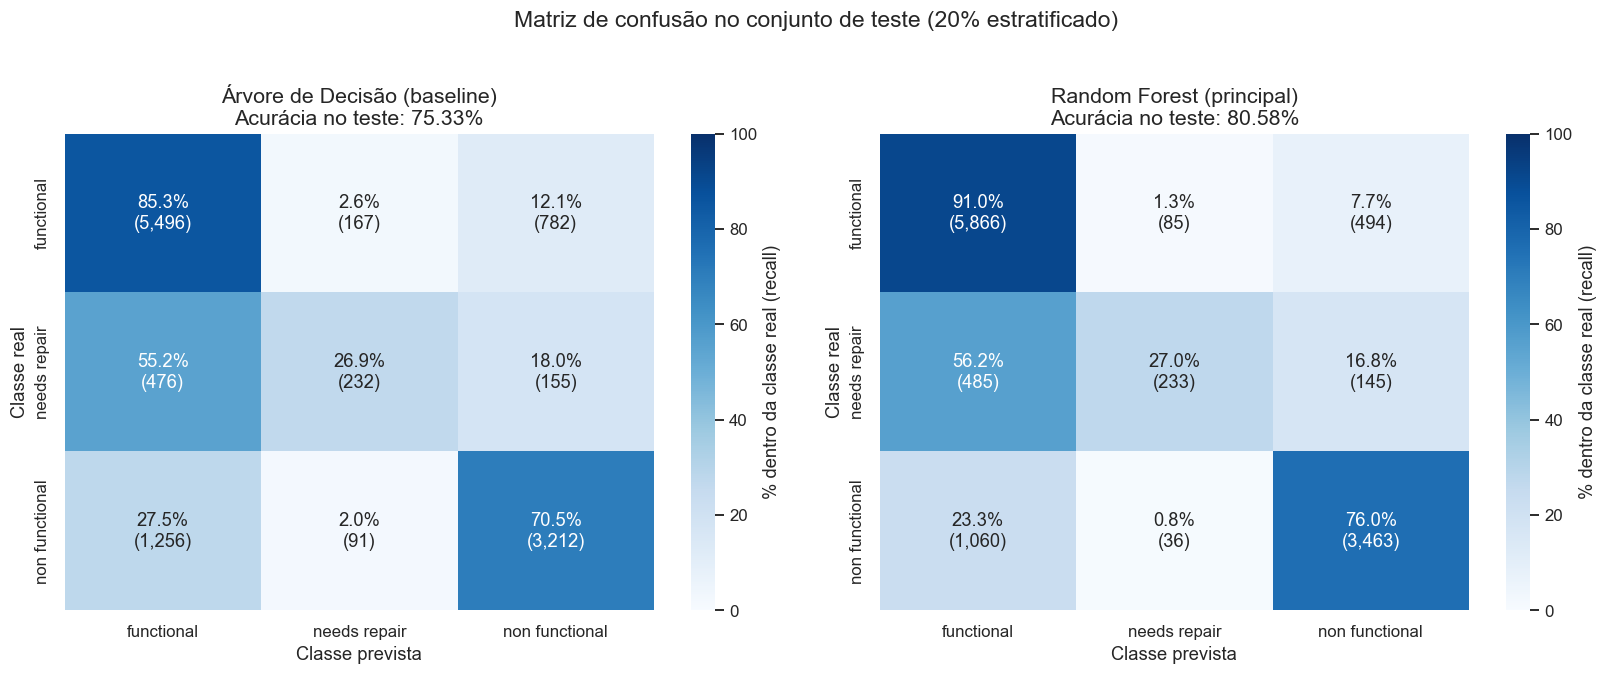

In [9]:
# [IA] Gemini – matrizes de confusão lado a lado (contagem + recall % por linha, paleta Blues)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

modelos_eval = [
    ("Árvore de Decisão (baseline)", pred_dt_test, acc_dt_test),
    ("Random Forest (principal)", pred_rf_test, acc_rf_test),
]

for ax, (nome, y_pred, acc) in zip(axes, modelos_eval):
    cm = confusion_matrix(y_test, y_pred, labels=STATUS_ORDEM)
    cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
    anot = np.array([[f"{cm_pct[i, j]:.1f}%\n({cm[i, j]:,})" for j in range(len(STATUS_ORDEM))] for i in range(len(STATUS_ORDEM))])
    sns.heatmap(
        cm_pct, annot=anot, fmt="", cmap="Blues", vmin=0, vmax=100,
        xticklabels=STATUS_CURTO, yticklabels=STATUS_CURTO,
        cbar_kws={"label": "% dentro da classe real (recall)"}, ax=ax,
    )
    ax.set_title(f"{nome}\nAcurácia no teste: {acc*100:.2f}%")
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real")

fig.suptitle("Matriz de confusão no conjunto de teste (20% estratificado)", fontsize=15, y=1.02)
fig.tight_layout()
salvar(fig, "06_matriz_confusao_modelos")
plt.show()

### 5.2 Tabela completa de métricas por classe (Acurácia, Precisão, Recall e F1)

Calcula e consolida todas as métricas cobradas na **Aula 26** para as três classes e exporta para `out/parte_especifica/06_metricas_classificadores.csv` (para consulta no relatório e no dashboard Streamlit).

> **Como ler:** `precisao` indica quantos dos previstos naquela classe realmente pertenciam a ela; `recall` indica quantos dos casos reais daquela classe o modelo encontrou; `f1` é a média harmônica entre precisão e recall; `suporte` é a quantidade real de registros daquela classe no teste.

In [10]:
# [IA] Gemini – tabela comparativa de acurácia, precisão, recall e F1 por classe + exportação CSV
linhas_met = []
for nome, y_pred, acc in [
    ("Arvore de Decisao", pred_dt_test, acc_dt_test),
    ("Random Forest", pred_rf_test, acc_rf_test),
]:
    prec, rec, f1, sup = precision_recall_fscore_support(y_test, y_pred, labels=STATUS_ORDEM, zero_division=0)
    for idx, cls in enumerate(STATUS_ORDEM):
        linhas_met.append({
            "modelo": nome,
            "classe": cls,
            "acuracia_global": round(acc * 100, 2),
            "precisao": round(prec[idx] * 100, 2),
            "recall": round(rec[idx] * 100, 2),
            "f1": round(f1[idx] * 100, 2),
            "suporte": int(sup[idx]),
        })
    # Macro F1 (dá o mesmo peso às 3 classes, importante com classe minoritária)
    linhas_met.append({
        "modelo": nome,
        "classe": "MEDIA MACRO (3 classes)",
        "acuracia_global": round(acc * 100, 2),
        "precisao": round(prec.mean() * 100, 2),
        "recall": round(rec.mean() * 100, 2),
        "f1": round(f1.mean() * 100, 2),
        "suporte": int(sup.sum()),
    })

df_metricas = pd.DataFrame(linhas_met)
df_metricas.to_csv(OUT_DIR / "06_metricas_classificadores.csv", index=False)

com_titulo(
    df_metricas.style.format({
        "acuracia_global": "{:.2f}%", "precisao": "{:.2f}%",
        "recall": "{:.2f}%", "f1": "{:.2f}%", "suporte": "{:,.0f}",
    }),
    "Tabela 5.1 — Métricas no conjunto de teste: Árvore de Decisão vs. Random Forest"
)

,modelo,classe,acuracia_global,precisao,recall,f1,suporte
0,Arvore de Decisao,functional,75.33%,76.04%,85.28%,80.39%,"6,445"
1,Arvore de Decisao,functional needs repair,75.33%,47.35%,26.88%,34.29%,863
2,Arvore de Decisao,non functional,75.33%,77.42%,70.45%,73.77%,"4,559"
3,Arvore de Decisao,MEDIA MACRO (3 classes),75.33%,66.93%,60.87%,62.82%,"11,867"
4,Random Forest,functional,80.58%,79.15%,91.02%,84.67%,"6,445"
5,Random Forest,functional needs repair,80.58%,65.82%,27.00%,38.29%,863
6,Random Forest,non functional,80.58%,84.42%,75.96%,79.97%,"4,559"
7,Random Forest,MEDIA MACRO (3 classes),80.58%,76.46%,64.66%,67.64%,"11,867"


### 5.3 Gráfico comparativo de Precisão, Recall e F1 por classe

Exibe lado a lado o desempenho dos dois modelos em cada uma das três classes de `status_group`.

> **Como ler:** Cada painel é uma métrica (Precisão, Recall e F1). Em cada classe no eixo X, a barra laranja mostra o baseline (Árvore de Decisão) e a barra azul mostra o Random Forest.

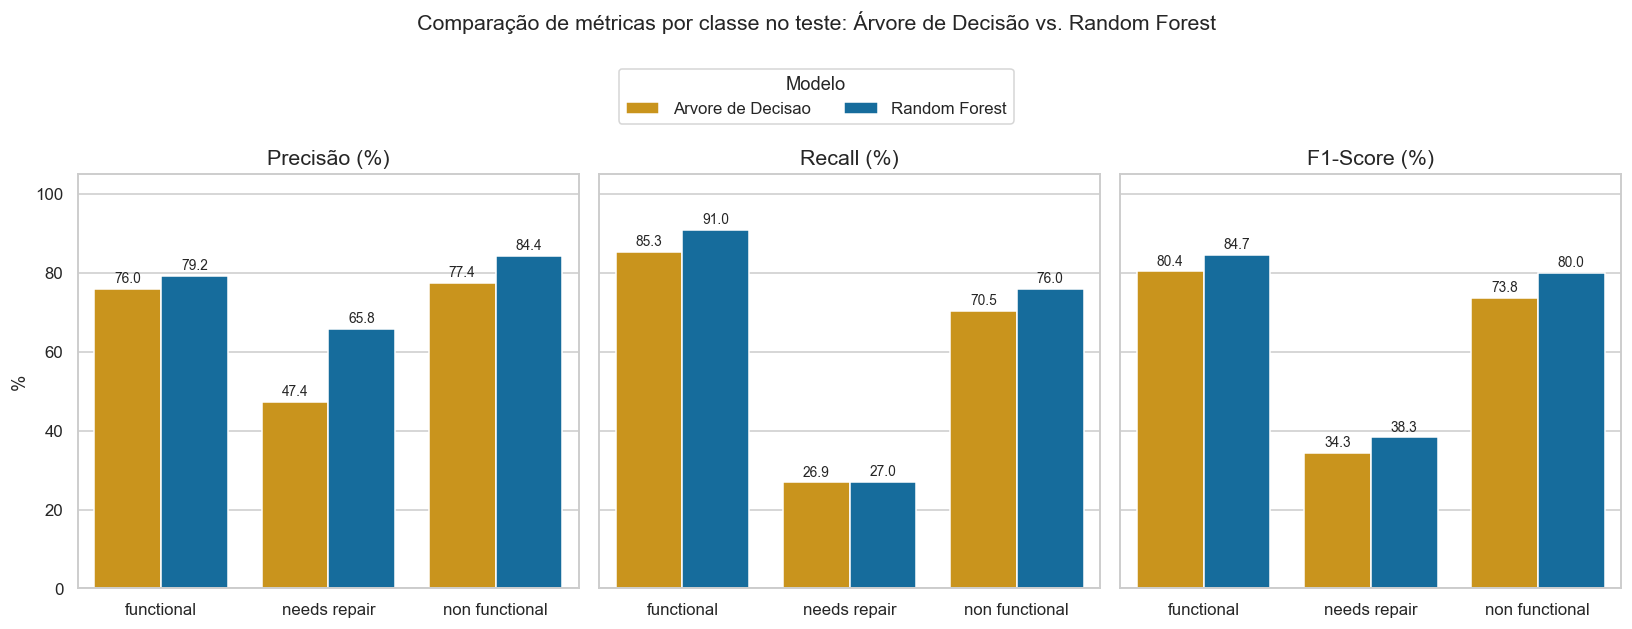

In [11]:
# [IA] Gemini – gráfico comparativo de Precisão, Recall e F1 por classe (Árvore vs. Random Forest)
df_plot = df_metricas[df_metricas["classe"].isin(STATUS_ORDEM)].copy()
df_plot["classe_curta"] = df_plot["classe"].map(dict(zip(STATUS_ORDEM, STATUS_CURTO)))

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
metricas_cols = [("precisao", "Precisão (%)"), ("recall", "Recall (%)"), ("f1", "F1-Score (%)")]

for ax, (col, titulo) in zip(axes, metricas_cols):
    sns.barplot(
        data=df_plot, x="classe_curta", y=col, hue="modelo",
        palette={"Arvore de Decisao": COR_DT, "Random Forest": COR_RF}, ax=ax,
    )
    ax.set_title(titulo)
    ax.set_xlabel("")
    ax.set_ylabel("%" if col == "precisao" else "")
    ax.set_ylim(0, 105)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f", fontsize=9, padding=2)
    if ax.get_legend():
        ax.get_legend().remove()

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Modelo", loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.05), frameon=True)
fig.suptitle("Comparação de métricas por classe no teste: Árvore de Decisão vs. Random Forest", fontsize=14, y=1.14)
fig.tight_layout()
salvar(fig, "06_comparativo_metricas_modelos")
plt.show()

### 5.4 Importância das variáveis no Random Forest (agregada por coluna original)

Soma a importância (`feature_importances_`) das colunas geradas pelo One-Hot Encoding e pelo Target Encoding de volta para o nome da coluna original do dataset, listando as 15 variáveis que mais pesaram nas divisões das 200 árvores do `RandomForestClassifier`.

> **O que este código faz (para explicar ao vivo):** como uma coluna categórica gera várias colunas após o encoding (ex.: `quantity` vira 5 colunas binárias no One-Hot; `installer` vira 3 colunas no Target Encoding), somamos a importância de todas as colunas derivadas de uma mesma variável original para obter a importância total de cada atributo.
>
> **Como ler:** Quanto maior a barra, maior a contribuição daquela variável na redução de impureza das árvores do Random Forest (a soma de todas as variáveis do modelo é 100%).

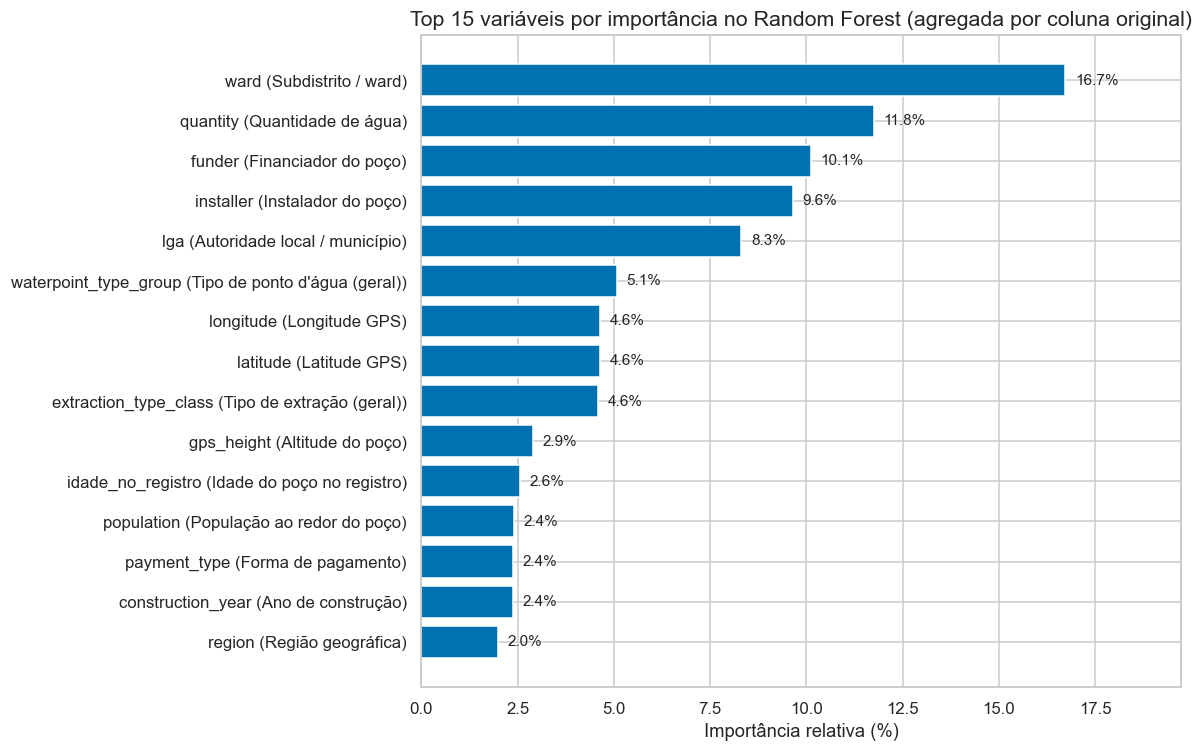

,coluna,glossario,importancia_pct
0,ward,Subdistrito / ward,16.73%
1,quantity,Quantidade de água,11.75%
2,funder,Financiador do poço,10.11%
3,installer,Instalador do poço,9.64%
4,lga,Autoridade local / município,8.31%
5,waterpoint_type_group,Tipo de ponto d'água (geral),5.08%
6,longitude,Longitude GPS,4.64%
7,latitude,Latitude GPS,4.63%
8,extraction_type_class,Tipo de extração (geral),4.58%
9,gps_height,Altitude do poço,2.90%


In [12]:
# [IA] Gemini – importância das features no Random Forest agregada por coluna original + exportação CSV/PNG
prep_rf = pipe_rf.named_steps["encoding"]
rf_model = pipe_rf.named_steps["modelo"]

# Mapeia cada coluna transformada de volta ao nome da coluna original
nomes_origem = []
nomes_origem.extend(COLS_NUM)  # passthrough: 1 para 1

ohe = prep_rf.named_transformers_["cat_baixa"]
for col, cats in zip(COLS_CAT_BAIXA, ohe.categories_):
    nomes_origem.extend([col] * len(cats))

# TargetEncoder multiclasse gera 1 coluna por classe (3 colunas) para cada feature em COLS_CAT_ALTA
n_classes = len(STATUS_ORDEM)
for col in COLS_CAT_ALTA:
    nomes_origem.extend([col] * n_classes)

assert len(nomes_origem) == len(rf_model.feature_importances_), (
    f"Divergência de colunas: {len(nomes_origem)} vs {len(rf_model.feature_importances_)}"
)

imp = (
    pd.DataFrame({"coluna": nomes_origem, "importancia": rf_model.feature_importances_})
    .groupby("coluna", as_index=False)["importancia"]
    .sum()
    .sort_values("importancia", ascending=False)
)
imp["importancia_pct"] = (imp["importancia"] * 100).round(2)
imp["glossario"] = imp["coluna"].map(lambda c: GLOSSARIO_COLUNAS.get(c, ""))
imp.to_csv(OUT_DIR / "06_importancia_features.csv", index=False)

top15 = imp.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 7))
rotulos = [f"{r.coluna} ({r.glossario})" if r.glossario else r.coluna for r in top15.itertuples()]
ax.barh(rotulos, top15["importancia_pct"], color=COR_RF)
for idx, val in enumerate(top15["importancia_pct"]):
    ax.text(val + 0.25, idx, f"{val:.1f}%", va="center", fontsize=10)
ax.set_title("Top 15 variáveis por importância no Random Forest (agregada por coluna original)")
ax.set_xlabel("Importância relativa (%)")
ax.set_ylabel("")
ax.set_xlim(0, top15["importancia_pct"].max() * 1.18)
fig.tight_layout()
salvar(fig, "06_importancia_features")
plt.show()

com_titulo(
    imp[["coluna", "glossario", "importancia_pct"]].head(15).reset_index(drop=True).style.format({"importancia_pct": "{:.2f}%"}),
    "Tabela 5.2 — Top 15 variáveis mais importantes no Random Forest"
)

<a id="sec-5-5"></a>

### 5.5 Demonstração prática: testando os modelos em 3 registros reais + auditoria da Árvore

Simula o uso prático por um gestor do Ministério de Águas: sorteia **3 pontos d'água reais do conjunto de teste** (registros que nenhum dos dois modelos viu no treino), aplica os modelos reais (`DecisionTreeClassifier` e `RandomForestClassifier`) e exibe:
1. A ficha resumida de cada ponto d'água sorteado;
2. A previsão e as **probabilidades (confiança)** de cada classe nos modelos escolhidos;
3. A **trilha de auditoria (`decision_path`) da Árvore de Decisão** — mostrando as perguntas exatas que a árvore fez da raiz até a folha para justificar sua decisão (algo que o Random Forest, por combinar 200 árvores em votação, não entrega em uma única regra simples).

> **O que este código faz (para explicar ao vivo):**
> - Você pode trocar `MODELO_ESCOLHIDO` para `"Ambos"`, `"Arvore de Decisao"` ou `"Random Forest"`, e mudar `SEED_SORTEIO` para sortear outras 3 bombas reais do teste (no **Streamlit**, isso vira o seletor de modelo + botão *"Sortear"* + botão *"Classificar"*!).
> - Na auditoria da Árvore, `pipe_dt.named_steps["modelo"].decision_path(...)` devolve exatamente os nós internos percorridos por aquele registro, traduzidos de volta para o nome da variável e o limiar de corte.
>
> **Como ler:** As tabelas mostram a ficha de cada bomba sorteada e a comparação entre classe prevista, classe real e probabilidades (%). O gráfico exibe as probabilidades previstas para as 3 classes em cada bomba, e o bloco de texto abaixo lista o caminho auditável percorrido pela Árvore de Decisão.

,id,region,lga,quantity,extraction_type_class,waterpoint_type_group,payment_type,idade_no_registro,funder,installer,status_group
exemplo,,,,,,,,,,,
Bomba #1,17915,Morogoro,Morogoro Rural,insufficient,handpump,hand pump,monthly,21,tanza,dwe,functional
Bomba #2,68762,Morogoro,Kilombero,seasonal,gravity,communal standpipe,monthly,1,ikela wa,ikela wa,functional needs repair
Bomba #3,65687,Tabora,Tabora Urban,dry,motorpump,communal standpipe,never pay,15,world bank,mwe,non functional


,exemplo,id,modelo,classe_real,classe_prevista,resultado,prob_functional,prob_needs_repair,prob_non_functional
0,Bomba #1,17915,Arvore de Decisao,functional,functional,Acertou,61.2%,18.4%,20.4%
1,Bomba #2,68762,Arvore de Decisao,functional needs repair,functional,Errou,100.0%,0.0%,0.0%
2,Bomba #3,65687,Arvore de Decisao,non functional,non functional,Acertou,0.1%,0.0%,99.9%
3,Bomba #1,17915,Random Forest,functional,functional,Acertou,62.9%,10.5%,26.6%
4,Bomba #2,68762,Random Forest,functional needs repair,functional,Errou,80.0%,12.8%,7.1%
5,Bomba #3,65687,Random Forest,non functional,non functional,Acertou,0.3%,0.0%,99.6%


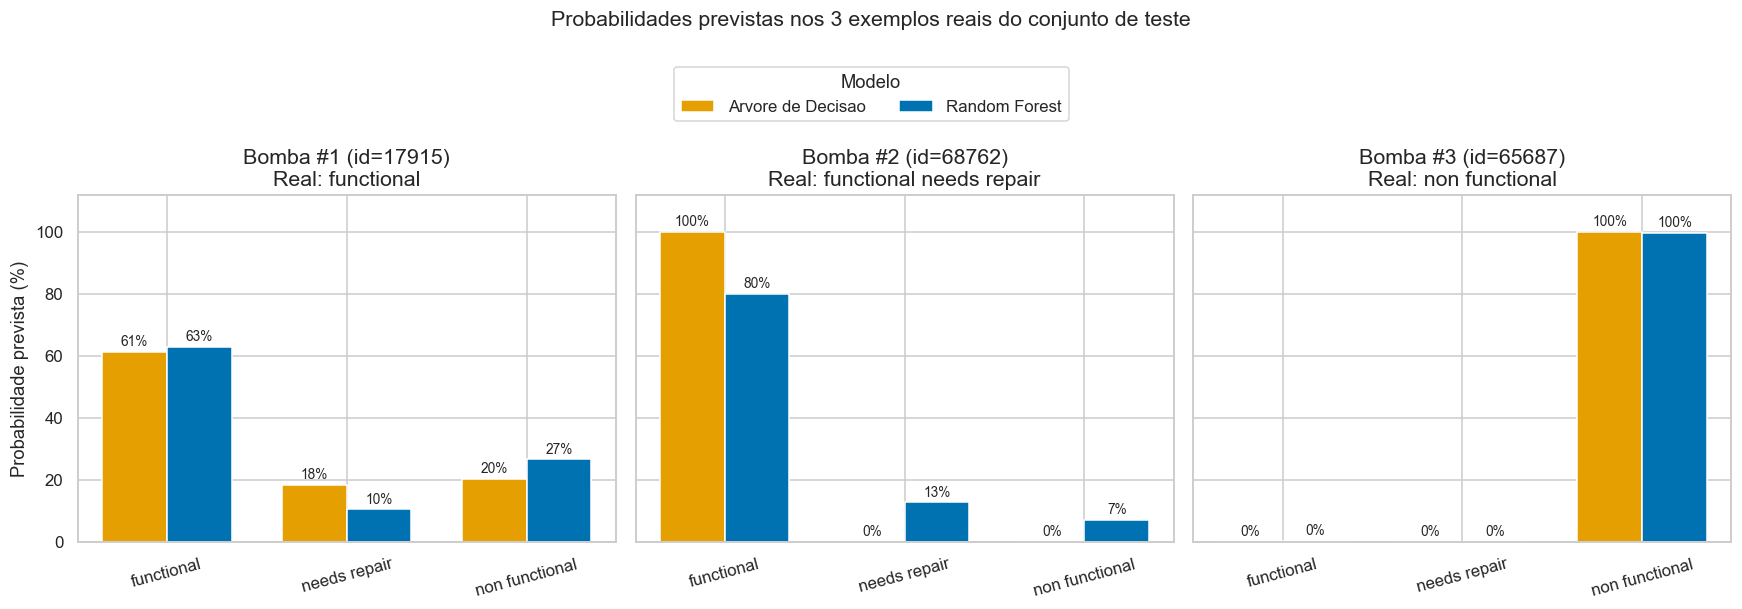

,Bomba #1 (id=17915 · Acertou),Bomba #2 (id=68762 · Errou),Bomba #3 (id=65687 · Acertou)
Passo 1,quantity == 'dry'? → NÃO,quantity == 'dry'? → NÃO,quantity == 'dry'? → SIM
Passo 2,TE(ward → functional) = 71.7% > 52.1%,TE(ward → functional) = 65.1% > 52.1%,TE(ward → needs repair) = 0.0% <= 47.4%
Passo 3,waterpoint_type_group == 'other'? → NÃO,waterpoint_type_group == 'other'? → NÃO,extraction_type_class == 'handpump'? → NÃO
Passo 4,TE(funder → non functional) = 51.9% > 41.3%,TE(funder → non functional) = 0.0% <= 41.3%,"construction_year = 1,997.0 <= 2,009.5"
Passo 5,TE(installer → functional) = 54.3% > 33.0%,TE(ward → functional) = 65.1% <= 79.5%,TE(ward → functional) = 5.2% <= 82.5%
Passo 6,payment_type == 'never pay'? → NÃO,TE(ward → needs repair) = 23.1% > 14.9%,region == 'Mwanza'? → NÃO
Passo 7,TE(ward → functional) = 71.7% > 65.5%,TE(funder → functional) = 80.9% > 62.5%,extraction_type_class == 'wind-powered'? → NÃO
Passo 8,TE(funder → functional) = 43.8% > 25.4%,idade_no_registro = 1.0 <= 7.5,management_group == 'commercial'? → NÃO
Passo 9,TE(lga → non functional) = 41.6% <= 69.0%,TE(funder → needs repair) = 14.3% > 2.6%,basin == 'Pangani'? → NÃO
Passo 10,quantity == 'enough'? → NÃO,ausente_coords = 0.0 <= 0.5,waterpoint_type_group == 'improved spring'? → NÃO


In [13]:
# [IA] Gemini – demonstração interativa em 3 registros reais do conjunto de teste + auditoria da Árvore de Decisão
MODELO_ESCOLHIDO = "Ambos"   # opções: "Ambos", "Arvore de Decisao" ou "Random Forest"
SEED_SORTEIO = 42            # troque este número e rode a célula para sortear outras 3 bombas
UM_DE_CADA_CLASSE = True     # True = 1 bomba real de cada classe; False = 3 totalmente aleatórias


def obter_nomes_features(preprocessador):
    """Retorna nomes legíveis de cada coluna após o ColumnTransformer (para auditar a Árvore)."""
    nomes = list(COLS_NUM)
    ohe = preprocessador.named_transformers_["cat_baixa"]
    for col, cats in zip(COLS_CAT_BAIXA, ohe.categories_):
        for cat in cats:
            nomes.append(f"{col} == '{cat}'")
    for col in COLS_CAT_ALTA:
        for cls in STATUS_CURTO:
            nomes.append(f"TE({col} → {cls})")
    return nomes


def auditar_arvore(pipe, linha_X, max_passos=8):
    """Extrai o caminho real de decisões (regras SE/ENTÃO) percorrido pela DecisionTreeClassifier."""
    X_imp = pipe.named_steps["imputacao"].transform(linha_X)
    X_enc = pipe.named_steps["encoding"].transform(X_imp)
    arvore = pipe.named_steps["modelo"].tree_
    nomes_feat = obter_nomes_features(pipe.named_steps["encoding"])

    caminho = pipe.named_steps["modelo"].decision_path(X_enc).indices
    regras = []
    for node_id in caminho[:-1]:  # o último nó é a folha (decisão final)
        feat_idx = arvore.feature[node_id]
        limiar = arvore.threshold[node_id]
        valor = float(X_enc[0, feat_idx])
        nome = nomes_feat[feat_idx]

        if " == '" in nome:
            # Variável One-Hot (0 ou 1): limiar é 0.5 -> traduz para SIM / NÃO legível
            cond = f"{nome}? → {'NÃO' if valor <= limiar else 'SIM'}"
        elif nome.startswith("TE("):
            sinal = "<=" if valor <= limiar else ">"
            cond = f"{nome} = {valor*100:.1f}% {sinal} {limiar*100:.1f}%"
        else:
            sinal = "<=" if valor <= limiar else ">"
            cond = f"{nome} = {valor:,.1f} {sinal} {limiar:,.1f}"
        regras.append(cond)

    folha = caminho[-1]
    contagens = arvore.value[folha][0]
    total_folha = int(arvore.n_node_samples[folha])
    return regras, len(regras), total_folha, contagens


def testar_exemplos(modelo="Ambos", seed=42, um_de_cada_classe=True):
    # 1) Sorteia 3 índices reais do conjunto de teste (nunca vistos no treino)
    if um_de_cada_classe:
        indices = []
        for cls in STATUS_ORDEM:
            idx_cls = y_test[y_test == cls].sample(1, random_state=seed).index[0]
            indices.append(idx_cls)
    else:
        indices = list(X_test.sample(3, random_state=seed).index)

    X_amostra = X_test.loc[indices]
    y_amostra = y_test.loc[indices]

    # 2) Ficha legível das 3 bombas sorteadas (usando valores originais/tratados de df)
    cols_ficha = [
        "id", "region", "lga", "quantity", "extraction_type_class",
        "waterpoint_type_group", "payment_type", "idade_no_registro",
        "funder", "installer", COL_ALVO,
    ]
    ficha = df.loc[indices, cols_ficha].copy()
    ficha.insert(0, "exemplo", [f"Bomba #{k}" for k in range(1, 4)])
    display(com_titulo(ficha.set_index("exemplo"), f"Tabela 5.3 — Ficha das 3 bombas reais sorteadas do teste (seed={seed})"))

    # 3) Classificação real nos modelos selecionados
    mapa_modelos = {
        "Arvore de Decisao": pipe_dt,
        "Random Forest": pipe_rf,
    }
    escolhidos = list(mapa_modelos.keys()) if modelo == "Ambos" else [modelo]

    linhas_res = []
    for nome_m in escolhidos:
        pipe = mapa_modelos[nome_m]
        preds = pipe.predict(X_amostra)
        probs = pipe.predict_proba(X_amostra)
        classes_pipe = list(pipe.classes_)
        idx_ordem = [classes_pipe.index(c) for c in STATUS_ORDEM]

        for k, (idx_row, real, pred, prob_vec) in enumerate(zip(indices, y_amostra, preds, probs), start=1):
            p_ord = prob_vec[idx_ordem] * 100
            linhas_res.append({
                "exemplo": f"Bomba #{k}",
                "id": int(df.loc[idx_row, "id"]),
                "modelo": nome_m,
                "classe_real": real,
                "classe_prevista": pred,
                "resultado": "Acertou" if pred == real else "Errou",
                "prob_functional": round(p_ord[0], 1),
                "prob_needs_repair": round(p_ord[1], 1),
                "prob_non_functional": round(p_ord[2], 1),
            })

    df_res = pd.DataFrame(linhas_res)
    display(com_titulo(
        df_res.style.format({
            "prob_functional": "{:.1f}%",
            "prob_needs_repair": "{:.1f}%",
            "prob_non_functional": "{:.1f}%",
        }),
        "Tabela 5.4 — Resultado da classificação real e probabilidades por classe"
    ))

    # 4) Gráfico de probabilidades por bomba sorteada
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
    for k, ax in enumerate(axes, start=1):
        sub = df_res[df_res["exemplo"] == f"Bomba #{k}"]
        real_k = sub["classe_real"].iloc[0]
        x = np.arange(len(STATUS_CURTO))
        largura = 0.36 if len(escolhidos) == 2 else 0.55
        for j, nome_m in enumerate(escolhidos):
            row_m = sub[sub["modelo"] == nome_m].iloc[0]
            vals = [row_m["prob_functional"], row_m["prob_needs_repair"], row_m["prob_non_functional"]]
            desloc = (-largura / 2 if j == 0 else largura / 2) if len(escolhidos) == 2 else 0
            cor = COR_DT if nome_m == "Arvore de Decisao" else COR_RF
            barras = ax.bar(x + desloc, vals, width=largura, label=nome_m, color=cor)
            ax.bar_label(barras, fmt="%.0f%%", fontsize=9, padding=2)
        ax.set_xticks(x)
        ax.set_xticklabels(STATUS_CURTO, rotation=15)
        ax.set_ylim(0, 112)
        ax.set_title(f"Bomba #{k} (id={int(df.loc[indices[k-1], 'id'])})\nReal: {real_k}")
        ax.set_ylabel("Probabilidade prevista (%)" if k == 1 else "")

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, title="Modelo", loc="upper center", ncol=len(escolhidos), bbox_to_anchor=(0.5, 1.06), frameon=True)
    fig.suptitle("Probabilidades previstas nos 3 exemplos reais do conjunto de teste", fontsize=14, y=1.15)
    fig.tight_layout()
    salvar(fig, "06_demo_exemplos_teste")
    plt.show()

    # 5) Auditoria da Árvore de Decisão em tabela lado a lado (evita truncamento no VS Code)
    if "Arvore de Decisao" in escolhidos:
        trilhas = {}
        resumo_folhas = {}
        max_prof = 0
        for k, idx_row in enumerate(indices, start=1):
            linha_X = X_amostra.loc[[idx_row]]
            regras, prof, n_folha, _ = auditar_arvore(pipe_dt, linha_X)
            row_dt = df_res[(df_res["exemplo"] == f"Bomba #{k}") & (df_res["modelo"] == "Arvore de Decisao")].iloc[0]
            col_nome = f"Bomba #{k} (id={row_dt['id']} · {row_dt['resultado']})"
            trilhas[col_nome] = regras
            resumo_folhas[col_nome] = f"Prevista: {row_dt['classe_prevista']} (real: {row_dt['classe_real']}, folha n={n_folha})"
            max_prof = max(max_prof, len(regras))

        dados_tab = {
            col_nome: regras + ["—"] * (max_prof - len(regras)) + [resumo_folhas[col_nome]]
            for col_nome, regras in trilhas.items()
        }
        idx_tab = [f"Passo {p}" for p in range(1, max_prof + 1)] + ["Decisão na folha"]
        df_audit = pd.DataFrame(dados_tab, index=idx_tab)
        display(com_titulo(
            df_audit.style.set_properties(**{"text-align": "left"}),
            "Tabela 5.5 — Auditoria da Árvore de Decisão: trilha real de perguntas da raiz até a folha (Random Forest usa votação de 200 árvores)"
        ))


testar_exemplos(modelo=MODELO_ESCOLHIDO, seed=SEED_SORTEIO, um_de_cada_classe=UM_DE_CADA_CLASSE)

<a id="sec-6"></a>

## 6. Interpretação autoral dos resultados

### ✅ [AUTORAL] 6.1 Análise dos resultados do classificador

> Os resultados no conjunto de teste (20% estratificado, sem data leakage) respondem à segunda parte da nossa pergunta de pesquisa e mostram que os atributos limpos na EDA permitem classificar a situação dos pontos d'água com bom desempenho, mas com limitações claras na classe minoritária. O `RandomForestClassifier` (200 árvores) superou o baseline `DecisionTreeClassifier` em todas as métricas principais, subindo de 75,33% para 80,58% de acurácia global e de 62,82% para 67,64% no Macro F1.

> Olhando por classe, o Random Forest consegue separar muito bem bombas funcionais (F1 de 84,67%, com recall de 91,02%) e não funcionais (F1 de 79,97%, com precisão de 84,42% e recall de 75,96%). O principal ponto de atenção continua sendo a classe minoritária `functional needs repair` (apenas 7,3% da base), que alcançou precisão de 65,82%, mas recall baixo de 27,00% (F1 de 38,29%). Na prática, isso significa que quando o modelo aponta que uma bomba precisa de reparo ele acerta na maioria das vezes, mas ainda deixa passar muitos casos reais dessa classe, classificando-os como funcionais (exatamente como aconteceu na Bomba #2 da demonstração 5.5).

> A importância das variáveis no Random Forest reforçou o que vimos na EDA: `quantity` ficou em 2º lugar (11,75%) mesmo sendo One-Hot de apenas 5 categorias, seguida de perto por `waterpoint_type_group` (5,08%), coordenadas geográficas (`longitude` e `latitude`) e `extraction_type_class` (4,58%). As 4 variáveis de alta cardinalidade com Target Encoding (`ward` com 16,73%, `funder` com 10,11%, `installer` com 9,64% e `lga` com 8,31%) ficaram entre as mais importantes tanto pelo sinal local e operacional real quanto pelo efeito natural do Target Encoding somado à importância por impureza nas árvores.

> Pensando no uso prático por um gestor do Ministério de Águas da Tanzânia em uma aplicação web (como faremos no dashboard Streamlit), fica evidente o trade-off entre os dois modelos: o Random Forest entrega maior acerto geral para priorizar manutenção em escala, enquanto a Árvore de Decisão, mesmo com acurácia um pouco menor, tem a grande vantagem de ser auditável passo a passo (como visto na Tabela 5.5), permitindo justificar por que cada ponto d'água recebeu determinada classificação.